# Bike-Sharing Demand — Exploratory Data Analysis

**Project type:** Exploratory Data Analysis (EDA) · Time-series analysis · Forecasting preparation  
**Domain:** Urban mobility / shared transportation  
**Dataset:** `day.csv` · **Period:** 1 January 2011–31 December 2012  
**Target:** `cnt` — total daily bike rentals

## Executive summary
This project explores daily bike-rental demand over time and its relationship with calendar patterns, weather, and previous demand. The dataset contains **731 daily observations and 16 columns**. Existing checks show no missing values, duplicate rows, duplicate dates, or missing calendar dates.

Initial findings show higher median demand in 2012 than 2011, variation by month and season, positive associations between temperature and rentals, lower observed demand in adverse weather categories, and strong autocorrelation. These are exploratory associations, not causal conclusions.

## Objective
Identify useful temporal, calendar, and weather patterns in daily bike demand and use the findings to plan a leakage-safe forecasting model.

## Business context
A bike-sharing operator can use demand forecasts to plan bike availability, redistribution, staffing, and maintenance. Forecasts should be evaluated on future dates, not randomly sampled observations.

## Business questions
1. How does daily demand change over the two-year period?
2. How does demand differ between 2011 and 2012?
3. Which months and seasons have the highest and lowest demand?
4. How does demand vary by weekday and working-day status?
5. How are temperature, humidity, wind speed, and weather categories associated with rentals?
6. Does demand show short-term or weekly temporal dependence?
7. What data-quality and leakage risks must be handled before forecasting?

## Scope and methods
Data-quality checks; daily and year-over-year trends; monthly and seasonal comparisons; weekday and working-day comparisons; weather correlations and category distributions; autocorrelation analysis at lags up to 30 days and selected lags 1, 2, 7, 14, and 28.

## Important modeling note
`cnt` equals `casual + registered`. **Exclude `casual` and `registered` from predictors** when predicting `cnt`, because they directly reveal the target. Exclude `instant` as an index-like identifier unless a justified use is established. Lag and rolling features must use only information available before the forecast date.

## Roadmap
1. Data quality and inspection
2. Overall and year-over-year trends
3. Monthly and seasonal demand
4. Weekday and working-day patterns
5. Weather relationships
6. Autocorrelation and selected lags
7. Findings, limitations, and next steps

---


In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf
import time

## 1. Load, inspect, and validate the data

Start with a quick structural review, then validate data quality and daily date continuity before interpreting demand patterns.

In [37]:
day_df = pd.read_csv("../data/raw/day.csv", parse_dates=["dteday"])

In [38]:
day_df.shape

(731, 16)

In [39]:
day_df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


In [40]:
day_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[ns]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[ns](1), floa

In [41]:
day_df.describe()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2012-01-01 00:00:00,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
min,1.000000,2011-01-01 00:00:00,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2011-07-02 12:00:00,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,2012-01-01 00:00:00,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,2012-07-01 12:00:00,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,2012-12-31 00:00:00,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000
std,211.165812,NaN,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452


In [42]:
day_df.isna().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [43]:
day_df.duplicated().sum()

np.int64(0)

### Data-quality checks

Check missing values, duplicate records and dates, target validity, and whether the daily time series has any calendar gaps.

In [44]:
# 1. Check data dimensions and column types
print("Shape:", day_df.shape)
display(day_df.dtypes)

# 2. Check missing values and duplicate rows
print("Missing values:\n", day_df.isna().sum())
print("Duplicate rows:", day_df.duplicated().sum())

# 3. Validate the date column
day_df["dteday"] = pd.to_datetime(day_df["dteday"])

print("Date range:", day_df["dteday"].min(), "to", day_df["dteday"].max())
print("Unique dates:", day_df["dteday"].nunique())
print("Dates sorted:", day_df["dteday"].is_monotonic_increasing)
print("Duplicate dates:", day_df["dteday"].duplicated().sum())

# 4. Check the target variable
print(day_df["cnt"].describe())
print("Negative rental counts:", (day_df["cnt"] < 0).sum())

Shape: (731, 16)


instant                int64
dteday        datetime64[ns]
season                 int64
yr                     int64
mnth                   int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object

Missing values:
 instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
Duplicate rows: 0
Date range: 2011-01-01 00:00:00 to 2012-12-31 00:00:00
Unique dates: 731
Dates sorted: True
Duplicate dates: 0
count     731.000000
mean     4504.348837
std      1937.211452
min        22.000000
25%      3152.000000
50%      4548.000000
75%      5956.000000
max      8714.000000
Name: cnt, dtype: float64
Negative rental counts: 0


### Daily date continuity

A daily forecasting workflow assumes that each calendar day is represented. Verify the full date range before analyzing temporal patterns.

In [45]:
print(day_df['dteday'].diff().value_counts())
full_dates = pd.date_range(
    start=day_df['dteday'].min(),
    end=day_df['dteday'].max(),
    freq='D'
)
missing_dates = full_dates.difference(day_df['dteday'])

print("Start date:", day_df['dteday'].min())
print("End date:", day_df['dteday'].max())
print("Total records:", len(day_df))
print("Expected daily records:", len(full_dates))
print("Missing dates:", len(missing_dates))

dteday
1 days    730
Name: count, dtype: int64
Start date: 2011-01-01 00:00:00
End date: 2012-12-31 00:00:00
Total records: 731
Expected daily records: 731
Missing dates: 0


In [46]:
assert len(full_dates) == len(day_df)
assert (day_df['dteday'].diff().iloc[1:] == pd.Timedelta(days=1)).all()

## 2. Exploratory Data Analysis
Perform EDA on this dataset to get the trends, demand over other features and analyse the dataset. 

### A. Demand Over Time
Visualise the Daily Demand over Time.

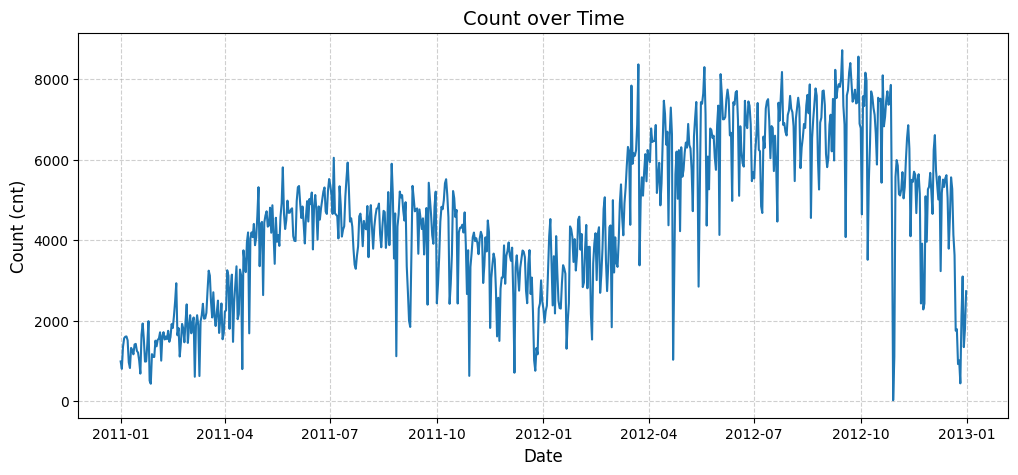

In [47]:

plt.figure(figsize=(12,5))
plt.plot(day_df["dteday"], day_df["cnt"])
plt.title("Count over Time", fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Count (cnt)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('../figures/demand_over_time.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

### B. Overall demand trend and year-over-year comparison

Compare the full daily series and each calendar year separately.

In [48]:
df_2011 = day_df[day_df["dteday"].dt.year==2011]
df_2012 = day_df[day_df["dteday"].dt.year==2012]

In [49]:
print(df_2011.shape)
print(df_2012.shape)

(365, 16)
(366, 16)


In [50]:
df_2011.describe()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,365.000000,365,365.000000,365.0,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000,365.000000
mean,183.000000,2011-07-02 00:00:00,2.498630,0.0,6.526027,0.027397,3.008219,0.684932,1.421918,0.486665,0.466835,0.643665,0.191403,677.402740,2728.358904,3405.761644
min,1.000000,2011-01-01 00:00:00,1.000000,0.0,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,9.000000,416.000000,431.000000
25%,92.000000,2011-04-02 00:00:00,2.000000,0.0,4.000000,0.000000,1.000000,0.000000,1.000000,0.325000,0.321954,0.538333,0.135583,222.000000,1730.000000,2132.000000
50%,183.000000,2011-07-02 00:00:00,3.000000,0.0,7.000000,0.000000,3.000000,1.000000,1.000000,0.479167,0.472846,0.647500,0.186900,614.000000,2915.000000,3740.000000
75%,274.000000,2011-10-01 00:00:00,3.000000,0.0,10.000000,0.000000,5.000000,1.000000,2.000000,0.656667,0.612379,0.742083,0.235075,871.000000,3632.000000,4586.000000
max,365.000000,2011-12-31 00:00:00,4.000000,0.0,12.000000,1.000000,6.000000,1.000000,3.000000,0.849167,0.840896,0.972500,0.507463,3065.000000,4614.000000,6043.000000
std,105.510663,NaN,1.110946,0.0,3.452584,0.163462,2.006155,0.465181,0.571831,0.189596,0.168836,0.148744,0.076890,556.269121,1060.110413,1378.753666


In [51]:
df_2012.describe()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,366.000000,366,366.000000,366.0,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000,366.000000
mean,548.500000,2012-07-01 12:00:00,2.494536,1.0,6.513661,0.030055,2.986339,0.683060,1.368852,0.504081,0.481852,0.612166,0.189572,1018.483607,4581.450820,5599.934426
min,366.000000,2012-01-01 00:00:00,1.000000,1.0,1.000000,0.000000,0.000000,0.000000,1.000000,0.107500,0.101658,0.254167,0.046650,2.000000,20.000000,22.000000
25%,457.250000,2012-04-01 06:00:00,2.000000,1.0,4.000000,0.000000,1.000000,0.000000,1.000000,0.347708,0.350685,0.508125,0.133721,429.750000,3730.500000,4369.000000
50%,548.500000,2012-07-01 12:00:00,2.500000,1.0,7.000000,0.000000,3.000000,1.000000,1.000000,0.514167,0.497779,0.611875,0.174750,904.500000,4776.500000,5927.000000
75%,639.750000,2012-09-30 18:00:00,3.000000,1.0,9.750000,0.000000,5.000000,1.000000,2.000000,0.653959,0.607646,0.711146,0.231196,1262.000000,5663.000000,7011.250000
max,731.000000,2012-12-31 00:00:00,4.000000,1.0,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.804913,0.925000,0.441563,3410.000000,6946.000000,8714.000000
std,105.799338,NaN,1.112185,0.0,3.455958,0.170971,2.006108,0.465921,0.516057,0.176112,0.156756,0.134206,0.078194,758.989897,1424.331846,1788.667868


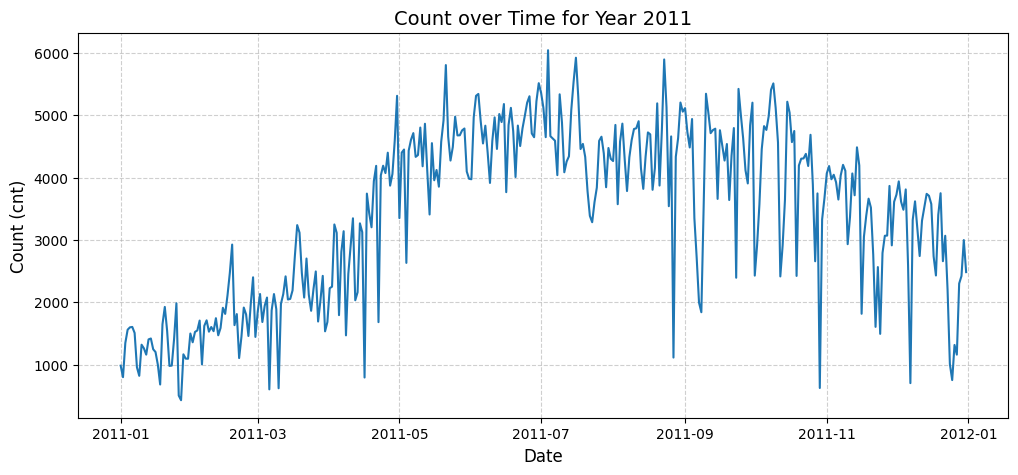

In [52]:
plt.figure(figsize=(12,5))
plt.plot(df_2011["dteday"], df_2011["cnt"])
plt.title("Count over Time for Year 2011", fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Count (cnt)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('../figures/demand_over_time_2011.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

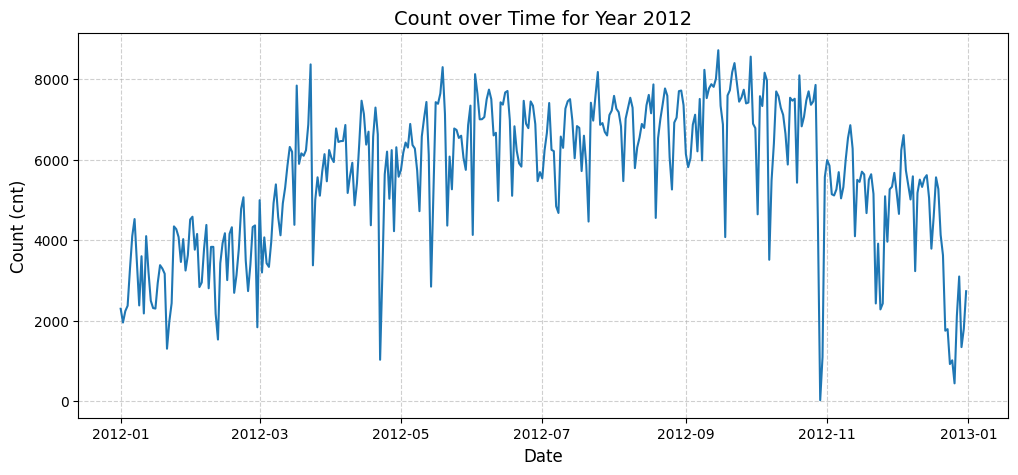

In [53]:
plt.figure(figsize=(12,5))
plt.plot(df_2012["dteday"], df_2012["cnt"])
plt.title("Count over Time for Year 2012", fontsize=14)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Count (cnt)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('../figures/demand_over_time_2012.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

In [54]:
print(df_2011["cnt"].median())
print(df_2012["cnt"].median())

3740.0
5927.0


### Year-over-year observation

- Median daily rentals increased from **3,740 in 2011** to **5,927 in 2012**.
- This is descriptive evidence; the two-year window alone does not establish the cause of the increase.

### C. Monthly demand patterns

Monthly averages highlight broad seasonal changes; the year-by-year comparison checks whether the pattern is consistent.

In [55]:
day_df['month'] = day_df['dteday'].dt.month_name()

month_order = [
    "January",
    "February",
    "March",
    "April",
    "May",
    "June",
    "July",
    "August",
    "September",
    "October",
    "November",
    "December",
    ]

overall_monthly_avg = (
    day_df.groupby("month")['cnt'].mean().reindex(month_order).reset_index()
)

overall_monthly_avg.columns = ["Month", "Average Demand"]
print(overall_monthly_avg)

        Month  Average Demand
0     January     2176.338710
1    February     2655.298246
2       March     3692.258065
3       April     4484.900000
4         May     5349.774194
5        June     5772.366667
6        July     5563.677419
7      August     5664.419355
8   September     5766.516667
9     October     5199.225806
10   November     4247.183333
11   December     3403.806452


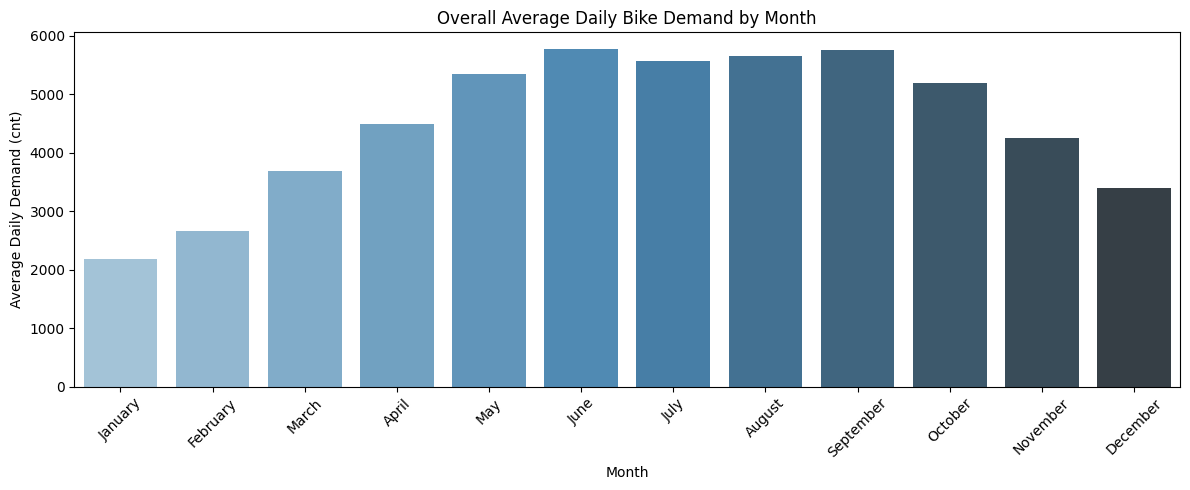

In [56]:
plt.figure(figsize=(12,5))
sns.barplot(data=overall_monthly_avg, x="Month", y="Average Demand", hue="Month", palette="Blues_d")
plt.title("Overall Average Daily Bike Demand by Month")
plt.xlabel("Month")
plt.ylabel("Average Daily Demand (cnt)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../figures/overall_monthly_demand.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

In [57]:
day_df["year"] = day_df["dteday"].dt.year
day_df["month_name"] = day_df["dteday"].dt.month_name()

monthly_by_year = (
    day_df.groupby(["year", "month_name"])['cnt'].mean().reset_index()
)

monthly_by_year["month_name"] = pd.Categorical(monthly_by_year["month_name"], categories=month_order, ordered=True)
monthly_by_year = monthly_by_year.sort_values("month_name")

#for yearly and monthly
pivoted_monthly = (
    monthly_by_year.pivot(index="month_name", columns="year", values="cnt").reindex(month_order).reset_index()
)

pivoted_monthly.columns.name = None
pivoted_monthly.columns = ["Month", "2011", "2012"]

print(pivoted_monthly)

        Month         2011         2012
0     January  1231.903226  3120.774194
1    February  1721.964286  3556.448276
2       March  2065.967742  5318.548387
3       April  3162.333333  5807.466667
4         May  4381.322581  6318.225806
5        June  4783.733333  6761.000000
6        July  4559.387097  6567.967742
7      August  4409.387097  6919.451613
8   September  4247.266667  7285.766667
9     October  3984.225806  6414.225806
10   November  3405.566667  5088.800000
11   December  2816.870968  3990.741935


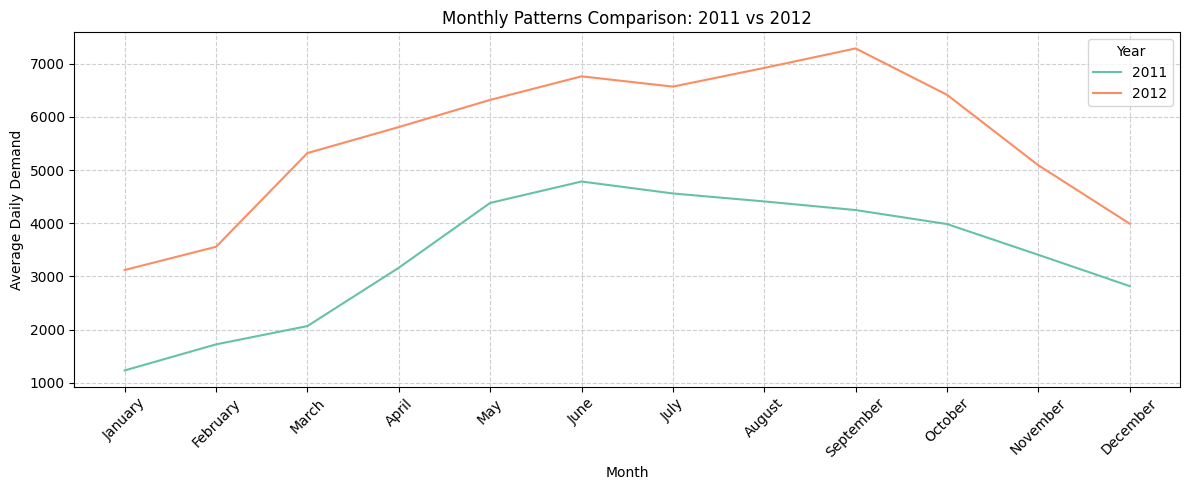

In [58]:
plt.figure(figsize=(12,5))
sns.lineplot(data=monthly_by_year, x="month_name", y="cnt", hue='year', markers="o", palette="Set2")
plt.title("Monthly Patterns Comparison: 2011 vs 2012")
plt.xlabel("Month")
plt.ylabel("Average Daily Demand")
plt.xticks(rotation=45)
plt.legend(title="Year")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig('../figures/seasonal_pattern_comparison.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

### Monthly and year-over-year observations

- Average demand is lowest in **January** and **February** and rises through spring.
- Overall monthly averages are highest in **June** and **September**; demand is comparatively high from May through September.
- Monthly demand is higher in 2012 than in 2011 for every month shown.
- With only two years of data, treat this as an initial seasonal signal rather than a stable long-term rule.
- **Forecasting note:** `casual` and `registered` sum to `cnt`; do not use them as predictors for `cnt`. `instant` is an index-like identifier and should generally be excluded.

### D. Demand distribution by month and season

The boxplot shows within-month spread, while the seasonal bar chart compares average demand across season categories.

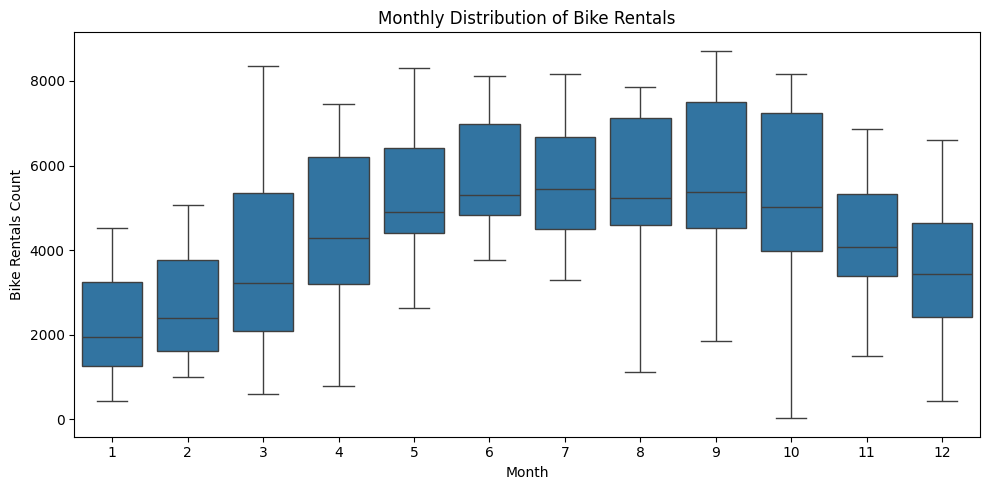

In [59]:
plt.figure(figsize=(10,5))
sns.boxplot(data=day_df, x='mnth', y='cnt')
plt.title('Monthly Distribution of Bike Rentals')
plt.xlabel('Month')
plt.ylabel('Bike Rentals Count')
plt.tight_layout()
plt.savefig('../figures/monthly_distribution_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

### Monthly distribution observations

- July, August, and September show relatively high rental distributions, while January and February are among the lowest-demand months.
- The boxplot shows within-month spread as well as central tendency; demand varies from day to day within a month.

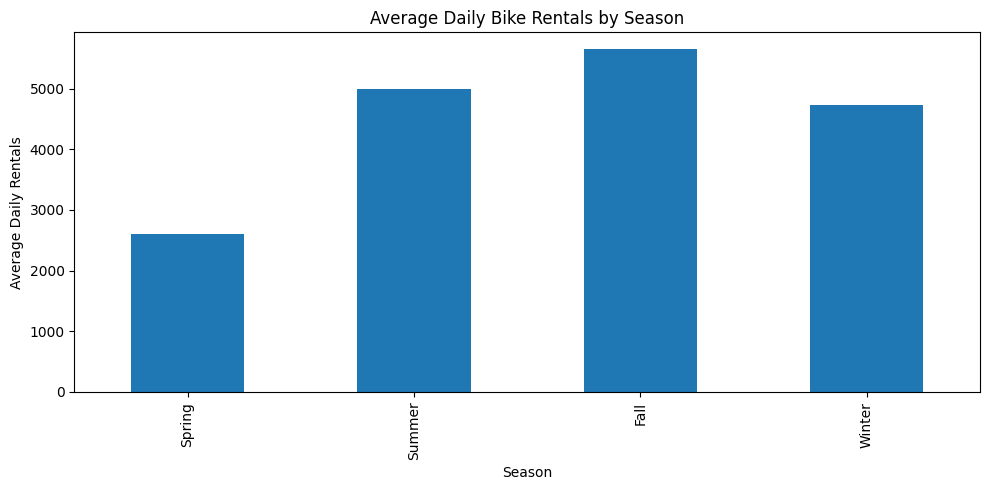

In [60]:
seasonal_demand = day_df.groupby("season")['cnt'].mean()
seasonal_demand.index = ['Spring', 'Summer', 'Fall', 'Winter']

seasonal_demand.plot(kind='bar', figsize=(10,5))
plt.title("Average Daily Bike Rentals by Season")
plt.xlabel("Season")
plt.ylabel("Average Daily Rentals")
plt.tight_layout()
plt.savefig('../figures/seasonal_distribution_plot.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

### Seasonal observation

- Average demand is highest in **fall**, followed by **summer** and **winter**; **spring** has the lowest average in this grouping.
- Confirm the season-code mapping when reusing the analysis with another data source.

### E. Calendar effects: weekday and working-day status

These comparisons are descriptive and should not be interpreted as causal effects.

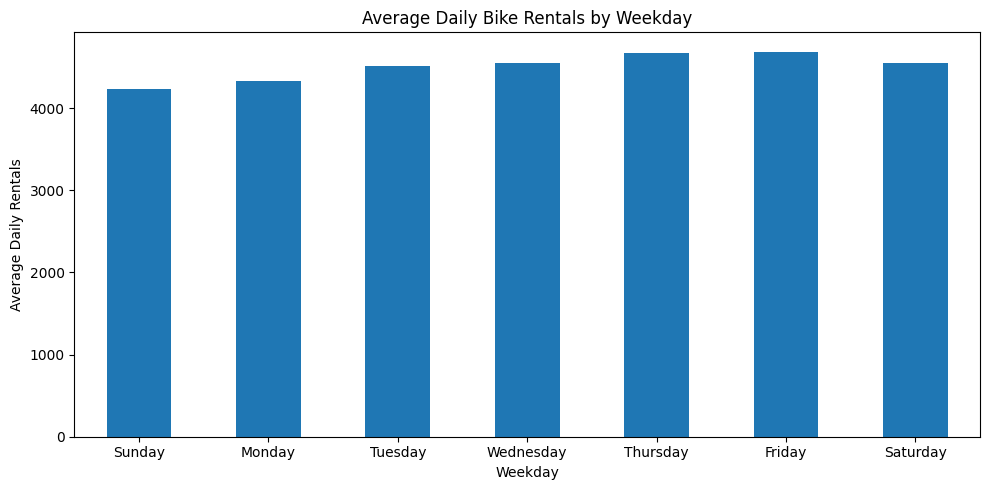

In [61]:
weekday_demand = day_df.groupby("weekday")['cnt'].mean()
weekday_demand.index = ["Sunday", "Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday"]

weekday_demand.plot(kind='bar', figsize=(10,5))
plt.title("Average Daily Bike Rentals by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Daily Rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../figures/Weekday_demand_plot.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

### Weekday observation

- Thursday and Friday have the highest average daily demand in this grouping, while Sunday has the lowest.
- These are descriptive differences and do not establish whether commuting, leisure, weather, or other factors cause them.

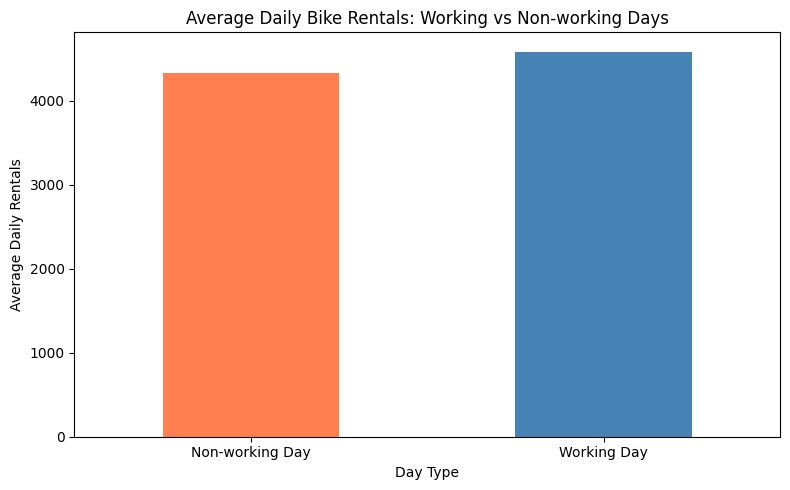

In [62]:
workingday_demand = day_df.groupby("workingday")["cnt"].mean()
workingday_demand.index = ["Non-working Day", "Working Day"]

workingday_demand.plot(kind='bar', figsize=(8,5), color=["coral", "steelblue"])
plt.title("Average Daily Bike Rentals: Working vs Non-working Days")
plt.xlabel("Day Type")
plt.ylabel("Average Daily Rentals")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../figures/Workingday_demand_plot.png', dpi=300, bbox_inches='tight')
plt.show()
plt.close()

### Working-day observation

- Average rentals are higher on working days than on non-working days in this dataset.
- `workingday` and `weekday` are related calendar variables; avoid interpreting these group differences as causal effects.

### F. Weather relationships

Correlation and grouped distributions explore associations between weather and rentals.

Correlation with total rentals (cnt):
atemp        0.631
temp         0.627
hum         -0.101
windspeed   -0.235
Name: cnt, dtype: float64


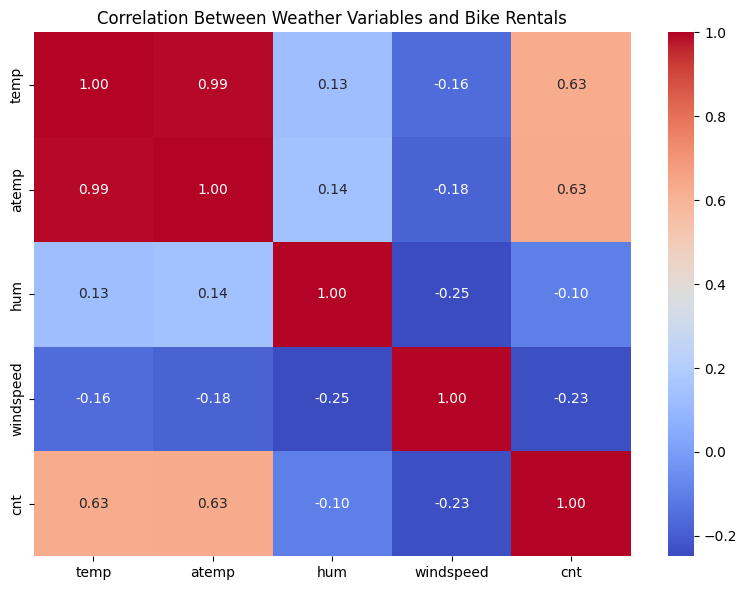

In [63]:
weather_cols = ["temp", "atemp", "hum", "windspeed", "cnt"]
weather_corr = day_df[weather_cols].corr()

print("Correlation with total rentals (cnt):")
print(weather_corr["cnt"].drop("cnt").sort_values(ascending=False).round(3))
plt.figure(figsize=(8,6))
sns.heatmap(weather_corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Weather Variables and Bike Rentals")
plt.tight_layout()
plt.savefig("../figures/Weather_correlation_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### Weather-correlation observations

- `temp` (**0.627**) and `atemp` (**0.631**) have the strongest positive pairwise correlations with rentals among the weather variables shown.
- `hum` has a weak negative correlation (**-0.101**), while `windspeed` has a negative correlation (**-0.235**).
- Correlation is not causation. Temperature and feels-like temperature are related, so their correlations should not be treated as independent effects.

In [64]:
weather_labels = {
    1: "Clear, Few clouds, Partly cloudy, Partly cloudy",
    2: "Mist + Cloudy, Mist + Broken clouds, Mist + Few clouds, Mist",
    3: "Light Snow, Light Rain + Thunderstorm + Scattered clouds, Light Rain + Scattered clouds",
    4: "Heavy Rain + Ice Pallets + Thunderstorm + Mist, Snow + Fog"
}

day_df["weather_label"] = day_df["weathersit"].map(weather_labels)

weather_demand = day_df.groupby(["weathersit", "weather_label"], observed=True).agg(
    avg_cnt=("cnt", "mean"),
    median_cnt=("cnt", "median"),
    days=("cnt", "size")
).reset_index()

print(weather_demand.round(2))

   weathersit                                      weather_label  avg_cnt  \
0           1    Clear, Few clouds, Partly cloudy, Partly cloudy  4876.79   
1           2  Mist + Cloudy, Mist + Broken clouds, Mist + Fe...  4035.86   
2           3  Light Snow, Light Rain + Thunderstorm + Scatte...  1803.29   

   median_cnt  days  
0      4844.0   463  
1      4040.0   247  
2      1817.0    21  


C:\Users\HP\AppData\Local\Temp\ipykernel_4644\452135855.py:7: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


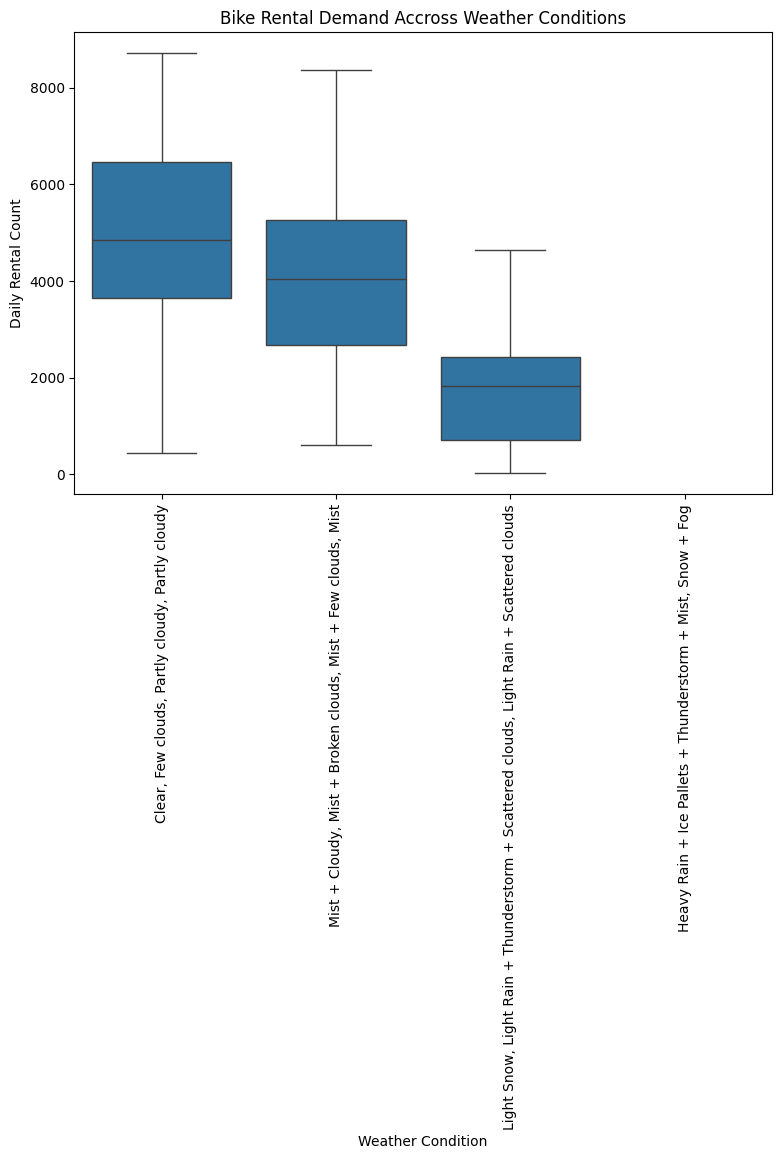

In [65]:
plt.figure(figsize=(9,6))
sns.boxplot(data=day_df, x="weather_label", y="cnt", order=list(weather_labels.values()))
plt.title("Bike Rental Demand Accross Weather Conditions")
plt.xlabel("Weather Condition")
plt.ylabel("Daily Rental Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig("../figures/weather_demand_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()
plt.close()

### Weather-category observations

- Average daily demand is highest in clear/fair conditions (**4,876.79 rentals**), lower in mist/cloudy conditions (**4,035.86**), and lower again in the light-rain/light-snow category (**1,803.29**).
- **No observations for weather category 4** appear in the grouped results. This analysis cannot estimate demand for that category; do not conclude that demand is zero during severe weather.
- Category counts are uneven (463, 247, and 21 days in categories 1–3), so category 3's estimate is based on a relatively small sample.

### G. Temporal dependence and autocorrelation

ACF plots summarize how current demand is associated with earlier observations.

<Figure size 1000x500 with 0 Axes>

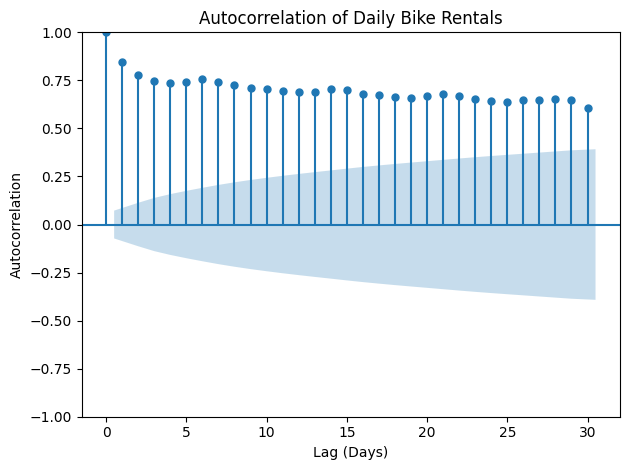

In [66]:
plt.figure(figsize=(10,5))
plot_acf(day_df["cnt"].dropna(), lags=30, alpha=0.05)
plt.title("Autocorrelation of Daily Bike Rentals")
plt.xlabel("Lag (Days)")
plt.ylabel("Autocorrelation")
plt.tight_layout()
plt.savefig("../figures/Bike_rental_ACF.png", dpi=300,bbox_inches="tight")
plt.show()
plt.close()

### Autocorrelation observation

- Daily rentals have strong positive autocorrelation at short lags, meaning nearby days tend to have similar rental counts.
- Positive autocorrelation at longer lags suggests temporal persistence. ACF alone does not prove seasonality; assess lag patterns and forecast performance on a chronological holdout.

In [67]:
lags_of_interest = [1, 2, 7, 14, 28]

acf_values = acf(
    day_df['cnt'].dropna(),
    nlags=max(lags_of_interest),
    fft=False
)

acf_results = {
    lag: acf_values[lag] for lag in lags_of_interest
}

for lag, value in acf_results.items():
    print(f"Lag {lag:2d} ({lag:2d} day(s)): {value:.4f}")
    

Lag  1 ( 1 day(s)): 0.8462
Lag  2 ( 2 day(s)): 0.7794
Lag  7 ( 7 day(s)): 0.7391
Lag 14 (14 day(s)): 0.7072
Lag 28 (28 day(s)): 0.6513


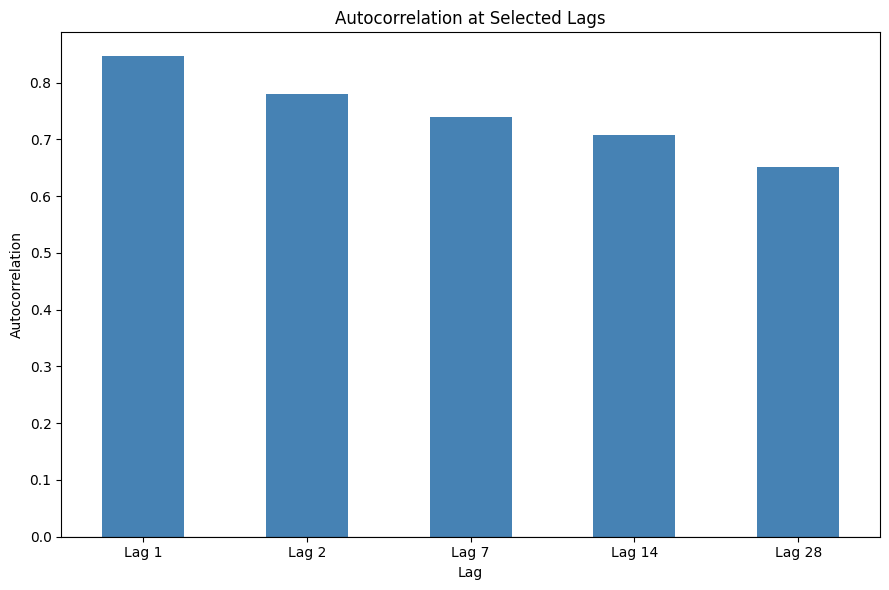

In [68]:
selected_acf = pd.Series({
    f"Lag {lag}": acf_values[lag] for lag in lags_of_interest
})

plt.figure(figsize=(9,6))
selected_acf.plot(kind='bar', color="steelblue")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Autocorrelation at Selected Lags")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("../figures/Selected_lag_ACF.png", dpi=300,bbox_inches="tight")
plt.show()
plt.close()

### Selected-lag observations

- Lag 1: **0.8462**
- Lag 2: **0.7794**
- Lag 7: **0.7391**
- Lag 14: **0.7072**
- Lag 28: **0.6513**

Lag 1 has the strongest selected correlation, while lag 7 is also strongly positive. The gradual decline suggests temporal dependence worth testing in forecasting, but does not prove any lag will improve out-of-sample accuracy.

# Final summary and next steps

## Main observations
1. **Data quality:** 731 daily records cover 1 January 2011 through 31 December 2012; checks find no missing values, duplicate rows, duplicate dates, or missing calendar dates.
2. **Year-over-year growth:** Median daily rentals increased from **3,740 in 2011** to **5,927 in 2012**.
3. **Monthly demand:** January and February have the lowest average demand; June and September are among the highest.
4. **Seasonality:** Average demand differs across season categories, with fall highest in this grouping.
5. **Calendar effects:** Thursday/Friday have the highest weekday averages in this analysis, and working days have higher average rentals than non-working days.
6. **Weather associations:** Temperature and feels-like temperature are positively correlated with demand; humidity and wind speed are negatively correlated.
7. **Weather limitation:** No category-4 observations appear in the grouped results, so demand for that category cannot be estimated from these records.
8. **Temporal dependence:** Rentals show positive autocorrelation at lags 1, 2, 7, 14, and 28 days.

## Limitations
- Only two calendar years are available, limiting long-term conclusions.
- Correlation and group averages do not establish causality.
- Weather-category sample sizes are uneven; category 3 has 21 observations and category 4 is absent.
- EDA does not establish predictive performance; forecast quality must be measured on a future holdout.
- `casual` and `registered` leak the target `cnt`; exclude them from predictors.

## Next planning: forecasting workflow
1. EDA notebook as the exploration record and create a separate feature-engineering notebook with different models training and compare the results.
2. Create calendar features and test demand lags at 1, 2, 3, 7, 14, 21, and 28 days.
3. Compute rolling statistics only after shifting the target so each feature uses past values only.
4. Exclude `casual`, `registered`, and `instant` from predictors.
5. Use a chronological split (no shuffle). A first experiment could train before **1 October 2012** and test on **1 October–31 December 2012**.
6. Compare simple baselines (previous-day demand and same-weekday demand from the prior week) with a small number of regression models.
7. Report MAE and RMSE, inspect errors over time and by season/weather, and compare each model against a baseline.
8. Train Random Forest and HistGradientBoosting models with baseline and hyperparameter tuning with RandomizedSearchCV and 5 fold cross validation and time series split.
9. Report the metrics and compare the models, inspect residuals over time.
10. Select the best model and add it to production code.
